#### 1. Import Libaries

In [2]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

# Import torch/transformers FIRST
import torch
from transformers import pipeline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from transformers import AutoTokenizer, AutoModelForSequenceClassification

#### 2. Data loading

In [3]:
df = pd.read_csv("PSN_articles.csv")

print(df.shape)

df

(193, 7)


,title,source,published,google_link,url,text,text_for_sentiment
0,Pemkab Ketapang Gandeng PSN Hadirkan Internet ...,Pontianak Post,2026-07-09 07:00:00+00:00,https://news.google.com/rss/articles/CBMi6wFBV...,https://pontianakpost.jawapos.com/ketapang/260...,NaN,Pemkab Ketapang Gandeng PSN Hadirkan Internet ...
1,PSN dan Telkomsat Ajukan Slot Orbit Satelit LE...,Bisnis Tekno,2026-07-08 07:00:00+00:00,https://news.google.com/rss/articles/CBMiywFBV...,https://teknologi.bisnis.com/read/20260708/101...,NaN,PSN dan Telkomsat Ajukan Slot Orbit Satelit LE...
2,"Dominasi Starlink Makin Kuat, PSN Sebut Era Sa...",Bisnis Tekno,2026-06-02 07:00:00+00:00,https://news.google.com/rss/articles/CBMizwFBV...,https://teknologi.bisnis.com/read/20260602/101...,NaN,"Dominasi Starlink Makin Kuat, PSN Sebut Era Sa..."
3,🛰️ Indonesia’s Nusantara Lima begins operation...,The Southeast Asia Desk,2026-05-19 07:00:00+00:00,https://news.google.com/rss/articles/CBMie0FVX...,https://www.thesoutheastasiadesk.com/p/indones...,🎯 The Main Takeaway\nIndonesia’s newest satell...,🎯 The Main Takeaway\nIndonesia’s newest satell...
4,Foto Bisnis SWA: Peresmian Operasional Satelit...,SWA.co.id,2026-05-17 07:00:00+00:00,https://news.google.com/rss/articles/CBMilAFBV...,https://swa.co.id/read/472659/foto-bisnis-swa-...,Foto Bisnis SWA: Peresmian Operasional Satelit...,Foto Bisnis SWA: Peresmian Operasional Satelit...
...,...,...,...,...,...,...,...
188,PSN-6 satellite (SSL),Teslarati,2019-01-15 12:19:49+00:00,https://news.google.com/rss/articles/CBMitgFBV...,https://www.teslarati.com/spacex-falcon-9-luna...,Elon Musk just confirmed the Tesla and SpaceX ...,Elon Musk just confirmed the Tesla and SpaceX ...
189,PSN Siap Luncurkan Satelit PSN VI Berkapasitas...,CNN Indonesia,2017-12-07 08:00:00+00:00,https://news.google.com/rss/articles/CBMiuwFBV...,https://www.cnnindonesia.com/teknologi/2017120...,"Jakarta, CNN Indonesia -- PT Pasifik Satelit N...","Jakarta, CNN Indonesia -- PT Pasifik Satelit N..."
190,"Bangun Satelit PALAPA-N1, PT Pasifik Satelit N...",JPNN.com,2017-05-22 07:00:00+00:00,https://news.google.com/rss/articles/CBMiqgFBV...,https://www.jpnn.com/news/bangun-satelit-palap...,"Bangun Satelit PALAPA-N1, PT Pasifik Satelit N...","Bangun Satelit PALAPA-N1, PT Pasifik Satelit N..."
191,Indosat-PSN beli satelit Palapa-N1 dari perusa...,ANTARA News,2017-05-17 07:00:00+00:00,https://news.google.com/rss/articles/CBMingFBV...,https://www.antaranews.com/berita/629703/indos...,Bisnis satelit itu bukan bisnis yang kita ngom...,Bisnis satelit itu bukan bisnis yang kita ngom...


#### 3. EDA

##### Dataframe info

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   title               193 non-null    object
 1   source              193 non-null    object
 2   published           193 non-null    object
 3   google_link         193 non-null    object
 4   url                 193 non-null    object
 5   text                160 non-null    object
 6   text_for_sentiment  193 non-null    object
dtypes: object(7)
memory usage: 10.7+ KB


In [5]:
df.isnull().sum()

title                  0
source                 0
published              0
google_link            0
url                    0
text                  33
text_for_sentiment     0
dtype: int64

##### Checking Duplicates

In [6]:
df["title"].str.lower().str.strip().duplicated().sum()

0

In [7]:
df["url"].duplicated().sum()

0

##### Dates of article published

In [8]:
# converting time to datetime
df["published"] = pd.to_datetime(df["published"], utc=True)
df["year"] = df["published"].dt.year

In [9]:
# showing articles from oldest to newest
print(df["published"].min())
print(df["published"].max())

2017-05-17 07:00:00+00:00
2026-07-09 07:00:00+00:00


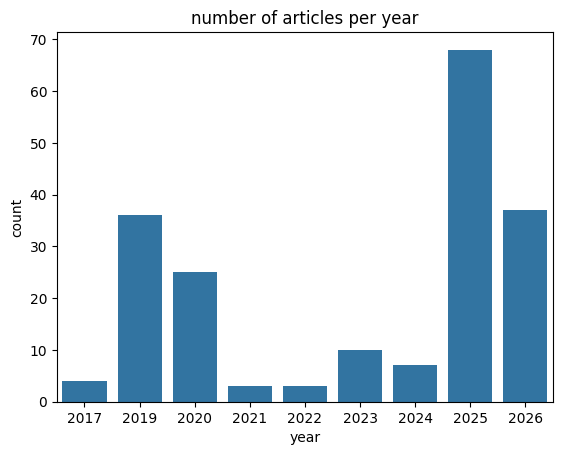

In [10]:
# number of articles per year
sns.countplot(data=df, x="year")
plt.title("number of articles per year")
plt.show()

##### Articles sources that dominates the most

In [11]:
print(df["source"].nunique())
df["source"].value_counts().head(10)

75


source
detikInet        34
Bisnis Tekno     13
Kompas.id        10
Suara.com        10
Tempo.co          9
Kumparan.com      9
ANTARA News       7
Kompas.com        6
InvestorTrust     5
kontan.co.id      4
Name: count, dtype: int64

##### The length of text 

count     193.0
mean      363.0
std       310.0
min         7.0
25%       124.0
50%       328.0
75%       511.0
max      1688.0
Name: word_count, dtype: float64


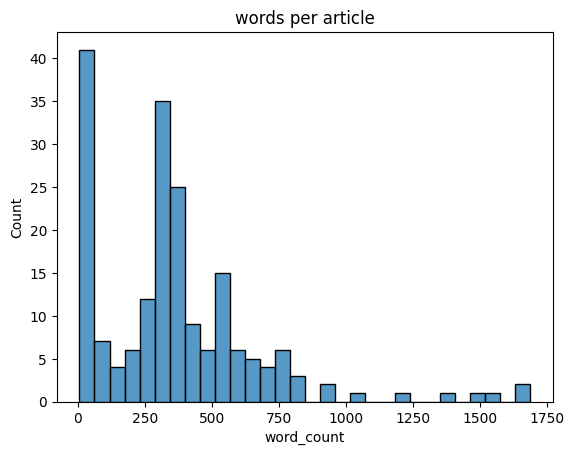

In [12]:
df["word_count"] = df["text_for_sentiment"].str.split().str.len()

print(df["word_count"].describe().round(0))

sns.histplot(data=df, x="word_count", bins=30)
plt.title("words per article")
plt.show()

here we can explore on how many articles that have only a title and how many that are fewer than 30 words from data scraping

In [13]:
print("title only:", df["text"].isnull().sum())

title only: 33


In [14]:
print("fewer than 30 words:", (df["word_count"] < 30).sum())

fewer than 30 words: 33


##### Finding what language the data dominates

In [15]:
first_part = df["text_for_sentiment"].str.lower().str[:500]
df["indo_words"] = first_part.str.count(r"\b(?:yang|dan|untuk|dengan|dari|pada|ini|satelit)\b")

df["language"] = np.where(df["indo_words"] >=3, "Indonesian", "English/other")

df["language"].value_counts()

language
Indonesian       141
English/other     52
Name: count, dtype: int64

##### Validating if the articles are about psn

In [16]:
keywords = "PSN|Pasifik Satelit|Pacific Satelite|Nusantara"
df["mentions_psn"] = df["text_for_sentiment"].str.contains(keywords, case=False, regex=True)

print(df["mentions_psn"].value_counts())

df[~df["mentions_psn"]][["title", "source"]]

mentions_psn
True     190
False      3
Name: count, dtype: int64


,title,source
37,Adi Rahman Adiwoso Raih Penghargaan Aerospace ...,Bisnis Tekno
127,"Adi Rahman Adiwoso, Teknologiwan Indonesia yan...",nukilan.id
188,PSN-6 satellite (SSL),Teslarati


#### 4. Data cleaning

the text from data scrapping is almost a mess with line breaks, extra spaces, duplicate and empty texts. this aims to clean the said text

In [17]:
# this cell will be for text cleaning

df["clean_text"] = df["text_for_sentiment"]

# replace line breaks with space
df["clean_text"] = df["clean_text"].str.replace("\n", " ", regex=True)

# removing domains
df["clean_text"] = df["clean_text"].str.replace("Dilarang keras mengambil konten.*?(?:situs web ini [.]|ANTARA[.])", "", regex=True)

# removing links
df["clean_text"] = df["clean_text"].str.replace("https?://[^ ]+", "", regex=True)

# change spaces into one space
df["clean_text"] = df["clean_text"].str.replace(" +", " ", regex=True)

# remove spaces at the start sentence and at the end of the sentence
df["clean_text"] = df["clean_text"].str.strip()

In [18]:
# Removing duplicate articles 
rows_before = df.shape[0]
df = df.drop_duplicates(subset="title")

# Removing articles if the content is none after cleaning
df = df[df["clean_text"].str.len() > 0]

# Reset row numbers after cleaning
df = df.reset_index(drop=True)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype              
---  ------              --------------  -----              
 0   title               193 non-null    object             
 1   source              193 non-null    object             
 2   published           193 non-null    datetime64[ns, UTC]
 3   google_link         193 non-null    object             
 4   url                 193 non-null    object             
 5   text                160 non-null    object             
 6   text_for_sentiment  193 non-null    object             
 7   year                193 non-null    int32              
 8   word_count          193 non-null    int64              
 9   indo_words          193 non-null    int64              
 10  language            193 non-null    object             
 11  mentions_psn        193 non-null    bool               
 12  clean_text          193 non-null    

checking the result of text before and after cleaning

In [19]:
print("Before:", round(df["text_for_sentiment"].str.len().mean()), "characters")
print("After:", round(df["clean_text"].str.len().mean()), "characters")

Before: 2675 characters
After: 2643 characters


#### 5. Adding lables using pre-trained sentiment model

##### Loading the model



the data i scraped doesn't come with sentiment, so i do a workaround by using a pre-trained sentiment model.

here i will be using ```lxyuan_distilbert``` and ```xlm_roberta``` to compare and to decide which one is better for labeling the PSN articles. I compare their label counts, agreement, and confidence scores

In [20]:
# model 1 Distilbert
lxyuan_distilbert_classifier = pipeline(
    "sentiment-analysis",
    model="lxyuan/distilbert-base-multilingual-cased-sentiments-student"
)

Device set to use cpu


In [21]:
# model 2: XLM-Roberta
tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-base")
model = AutoModelForSequenceClassification.from_pretrained("cardiffnlp/twitter-xlm-roberta-base-sentiment")

xlm_roberta_base = pipeline(
    "sentiment-analysis", 
    model=model, 
    tokenizer=tokenizer)

Device set to use cpu


In [22]:
texts = df["clean_text"].tolist()

#loading two models
distilbert_result = lxyuan_distilbert_classifier(texts, truncation=True, max_length=512, batch_size=8)
xlm_result = xlm_roberta_base(texts, truncation=True, max_length=512)

##### Label Comparison on each models

In [23]:
# put both results into a seperate table
compare_df = pd.DataFrame({
    "text": texts,
    "label_distilbert": pd.DataFrame(distilbert_result)["label"].str.lower(),
    "score_distilbert": pd.DataFrame(distilbert_result)["score"],
    "label_xlm": pd.DataFrame(xlm_result)["label"].str.lower(),
    "score_xlm": pd.DataFrame(xlm_result)["score"]
})

compare_df.head(10)


,text,label_distilbert,score_distilbert,label_xlm,score_xlm
0,Pemkab Ketapang Gandeng PSN Hadirkan Internet ...,positive,0.546819,positive,0.579546
1,PSN dan Telkomsat Ajukan Slot Orbit Satelit LE...,positive,0.545614,neutral,0.703243
2,"Dominasi Starlink Makin Kuat, PSN Sebut Era Sa...",positive,0.660443,positive,0.473927
3,🎯 The Main Takeaway Indonesia’s newest satelli...,positive,0.467914,neutral,0.460888
4,Foto Bisnis SWA: Peresmian Operasional Satelit...,positive,0.551659,neutral,0.721646
5,Can't find what you're looking for? View all s...,positive,0.635248,neutral,0.461794
6,The Nusantara Lima Satellite has officially co...,positive,0.821756,neutral,0.422207
7,Satelit Nusantara Lima Menjadi Satelit Terbesa...,positive,0.555935,neutral,0.657592
8,"PSN Gelontorkan Investasi Lebih Rp 23 Triliun,...",positive,0.729301,neutral,0.531458
9,"Tantang Starlink, PSN Andalkan Satelit Lokal d...",positive,0.598618,neutral,0.558645


##### Label distribution
here, i want to see the difference of sentiment distribution by comparing each label on each model

In [24]:
# showing the comparison dataframe
pd.DataFrame({
    "distilbert": compare_df["label_distilbert"].value_counts(),
    "xlm": compare_df["label_xlm"].value_counts()
})

,distilbert,xlm
negative,32,4
neutral,2,177
positive,159,12


based on this result, Distilbert has 159 positive, but xlm has 177 neutral. the two models labels the data very differently.

##### Comparing confidence score
here i will be comparing both confidence scores, the higher the score the better the model at labeling

In [25]:
print("DistilBERT avg score:", compare_df["score_distilbert"].mean())
print("XLM avg score:", compare_df["score_xlm"].mean())

DistilBERT avg score: 0.6558425233462931
XLM avg score: 0.5616082382325681


The average confidence is close: DistilBERT is 0.66 and XLM is 0.56. Both scores are fairly low, which means neither model is very sure about its labels on these news articles. Confidence alone cannot tell me which model is better.

##### Comparing pre trained model evaluation metrics by manually labeled data

since confidence score alone cannot make me decide which pre trained model that i will be using. i will try to label 80 articles based on titles, then compares them from evaluation metrics.

In [26]:
labels = pd.read_csv("labeled_sample.csv", index_col=0)
labeled = compare_df.join(labels["true_label"], how="inner")
print(labeled.shape)   # should print (80, 6)

(80, 6)


In [27]:
print("DistilBERT")
print(classification_report(labeled["true_label"], labeled["label_distilbert"]))

print("XLM")
print(classification_report(labeled["true_label"], labeled["label_xlm"]))

DistilBERT
              precision    recall  f1-score   support

    negative       0.64      0.88      0.74         8
     neutral       0.00      0.00      0.00        42
    positive       0.41      0.93      0.57        30

    accuracy                           0.44        80
   macro avg       0.35      0.60      0.44        80
weighted avg       0.22      0.44      0.29        80

XLM
              precision    recall  f1-score   support

    negative       0.67      0.25      0.36         8
     neutral       0.55      0.93      0.69        42
    positive       0.50      0.10      0.17        30

    accuracy                           0.55        80
   macro avg       0.57      0.43      0.41        80
weighted avg       0.54      0.55      0.46        80



Cutting to the important part of evaluation metrics :
- accuracy
- f1
so i can compare them based on the two metrics

In [28]:
compare_metrics_model = pd.DataFrame({
    "model": ["distilbert", "xlm"],
    "accuracy": [
        accuracy_score(labeled["true_label"], labeled["label_distilbert"]),
        accuracy_score(labeled["true_label"], labeled["label_xlm"])
    ],
    "f1": [
        f1_score(labeled["true_label"], labeled["label_distilbert"], average="macro"),
        f1_score(labeled["true_label"], labeled["label_xlm"], average="macro")
    ]
})

compare_metrics_model.round(3)

,model,accuracy,f1
0,distilbert,0.438,0.436
1,xlm,0.550,0.407


based on the results of evaluation metrics we can gather the results :

| | Macro F1 | Accuracy | Negative found | Positive found | Neutral found |
|---|---|---|---|---|---|
| DistilBERT | 0.44 | 0.44 | 7 of 8 | 28 of 30 | 0 of 42 |
| XLM | 0.41 | 0.55 | 2 of 8 | 3 of 30 | 39 of 42 |

we can analyze that 
- DistilBERT over-predicts positive and almost never says neutral.
- XLM over-predicts neutral and misses most positive and negative articles.
- XLM's higher accuracy is misleading: 52% of the sample is neutral, so always answering "neutral" would score almost the same.

hence, i decided to use **DistilBERT** for the rest of the project. the main reason is because to measure sentiment, DistilBERT detects positive and negative articles much efficient. meanwhwile XLM would label almost every article neutral, leaving little sentiment to analyze

##### Adding lables with distilbert

here i will be reusing its results from distilbert. the model will give labels and confidence score.

In [29]:
# Distilbert results
results_df = pd.DataFrame(distilbert_result)

# Adding the lables and confidence scores to main table
df["sentiment_pretrained"] = results_df["label"]
df["confidence"] = results_df["score"]

df[["title", "sentiment_pretrained", "confidence"]].head(10)

,title,sentiment_pretrained,confidence
0,Pemkab Ketapang Gandeng PSN Hadirkan Internet ...,positive,0.546819
1,PSN dan Telkomsat Ajukan Slot Orbit Satelit LE...,positive,0.545614
2,"Dominasi Starlink Makin Kuat, PSN Sebut Era Sa...",positive,0.660443
3,🛰️ Indonesia’s Nusantara Lima begins operation...,positive,0.467914
4,Foto Bisnis SWA: Peresmian Operasional Satelit...,positive,0.551659
5,PSN’s Nusantara 5 satellite officially starts ...,positive,0.635248
6,Nusantara Lima Satellite Expands Indonesia’s A...,positive,0.821756
7,Satelit Nusantara Lima Menjadi Satelit Terbesa...,positive,0.555935
8,"PSN Gelontorkan Investasi Lebih Rp 23 Triliun,...",positive,0.729301
9,"Tantang Starlink, PSN Andalkan Satelit Lokal d...",positive,0.598618


##### Checking labels

here i will doing EDA for data that has been labeled from distilbert, where I looked at 15 random articles and at the articles where the model is unsure (confidence below 0.6).

In [ ]:
# checking the labels of 15 random articles
pd.set_option("display.max_colwidth", 100)
df[["title", "sentiment_pretrained", "confidence"]].sample(15, random_state=42)

,title,sentiment_pretrained,confidence
45,"Setelah Mengorbit, Apa Manfaat Satelit Nusantara Lima bagi Indonesia?",positive,0.671746
137,"Satelit Nusantara Dua Gagal Mengorbit, Layanan Penyiaran Tetap Aman",negative,0.515844
76,Bos PSN Optimistis Satelit Nusantara Lima Meluncur ke Angkasa Hari Ini,negative,0.568133
144,Satelit Nusantara Dua Gagal Mengorbit Karena Masalah Teknis,negative,0.756740
113,"Perkuat Ekosistem Satelit Nasional, PSN dan BRIN Umumkan Kemitraan Strategis",positive,0.857547
152,"Akses Internet Terbatas, PSN Hadirkan Ubiqu Sinyalku untuk Daerah Pelosok",positive,0.649903
15,"Indonesia luncurkan Satelit Nusantara Lima, percepat pemerataan internet",positive,0.861967
18,Berita Kini - Menkomdigi Meutya Hafid: Satelit Nusantara Lima Bukti Nyata Kedaulatan Digital Ind...,positive,0.594149
16,"Satelit Nusantara Lima Dilirik Filipina dan Malaysia, PSN Klaim Terbesar di Asia",positive,0.824397
9,"Tantang Starlink, PSN Andalkan Satelit Lokal dan Antena Buatan Dalam Negeri",positive,0.598618


In [ ]:
# showing labels below 0.6 confidence score
df[df["confidence"] < 0.6][["title", "sentiment_pretrained", "confidence"]]

,title,sentiment_pretrained,confidence
0,"Pemkab Ketapang Gandeng PSN Hadirkan Internet ke Desa Blank Spot, Akses Digital Ditargetkan Maki...",positive,0.546819
1,"PSN dan Telkomsat Ajukan Slot Orbit Satelit LEO ke ITU, Ingin Saingi Starlink",positive,0.545614
3,"🛰️ Indonesia’s Nusantara Lima begins operations, boosting digital connectivity and space ambitions",positive,0.467914
4,Foto Bisnis SWA: Peresmian Operasional Satelit Nusantara Lima,positive,0.551659
7,Satelit Nusantara Lima Menjadi Satelit Terbesar di Asia yang Berspesifikasi Very High Throughput...,positive,0.555935
...,...,...,...
181,"Siap-Siap, Satelit Nusantara Satu ""Mengangkasa"" Besok",positive,0.467954
187,Satelit Kapasitas Jumbo Nusantara Satu Mengorbit pada Februari,positive,0.488678
188,PSN-6 satellite (SSL),negative,0.466345
189,PSN Siap Luncurkan Satelit PSN VI Berkapasitas 15 Gbps,positive,0.592772




From the random 15 sample, i can conclude that 
- The model gave 12 positive, 3 negative and **0 neutral** labels.
- the two articles about Nusantara Dua failing to reach orbit are negative, and articles about successful launches (for example "Nusantara Tiga Sukses Sampai di Orbit") are positive.
- Some labels misses their predictions. "Bos PSN Optimistis ... Meluncur Hari Ini" is negative (0.57), although the title sounds positive. "Apa Manfaat Satelit Nusantara Lima bagi Indonesia?" and the partnership articles (PSN and BRIN, Kominfo and PSN) are positive, but they are informational, so it would be neutral.

From articles that has the confidence score below 0.6, i can conclude that 
- In the rows shown, almost all are positive, and many are factual announcements. for example, an orbit slot application, a satellite purchase, a photo caption, even a satellite name ("PSN-6 satellite (SSL)", labeled negative). These are neutral news.
- "SpaceX Sukses Luncurkan..." is clearly positive but only has 0.45. the BRIN partnership, which was talking about factual articles has 0.86 is positive. This shows that the model is simply inconsistent and struggles to guess its own accuracy.


with all of the above, i can gather that  The model works well for clear good or bad events (success, failure), but it tends to label neutral, informational news as positive. So the positive count is probably too high. This matches the reference sample result in Distilbert Lablelling, where DistilBERT almost never predicted neutral.

#### 6. Modelling: Logistic Regression and Naive Bayes

##### Splitting into train and test set 

In [33]:
X = df["clean_text"]
y = df["sentiment_pretrained"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])

Train size: 154
Test size: 39


##### Turn text into numbers (TF-IDF)

In [34]:
vectorizer = TfidfVectorizer(max_features=5000, min_df=2)

X_train_tfidf = vectorizer.fit_transform(X_train)

X_test_tfidf = vectorizer.transform(X_test)

print(X_train_tfidf.shape)

(154, 3057)


##### Logistic regression model definition

In [42]:
logreg_model = LogisticRegression(max_iter=1000)

logreg_model.fit(X_train_tfidf, y_train)

logreg_pred = logreg_model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, logreg_pred))
print(classification_report(y_test, logreg_pred))

Accuracy: 0.9230769230769231
              precision    recall  f1-score   support

    negative       1.00      0.57      0.73         7
    positive       0.91      1.00      0.96        32

    accuracy                           0.92        39
   macro avg       0.96      0.79      0.84        39
weighted avg       0.93      0.92      0.91        39



##### Naive bayes model definition

In [45]:
Naive_model = MultinomialNB()

Naive_model.fit(X_train_tfidf, y_train)

Naive_pred = Naive_model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, Naive_pred))
print(classification_report(y_test, Naive_pred))


Accuracy: 0.8205128205128205
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         7
    positive       0.82      1.00      0.90        32

    accuracy                           0.82        39
   macro avg       0.41      0.50      0.45        39
weighted avg       0.67      0.82      0.74        39



c:\conda3\envs\h8_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\conda3\envs\h8_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\conda3\envs\h8_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


##### Model Score Comparing

In [47]:
model_compare = pd.DataFrame({
    "model": ["LogisticRegression", "Naive Bayes"],
    "accuracy": [accuracy_score(y_test, logreg_pred), accuracy_score(y_test, Naive_pred)],
    "f1": [f1_score(y_test, logreg_pred, average="macro"), f1_score(y_test, Naive_pred, average="macro")]
})

model_compare.round(3)

,model,accuracy,f1
0,LogisticRegression,0.923,0.841
1,Naive Bayes,0.821,0.451


Based on these metrics, Logistic Regression performs better than Naive Bayes on both accuracy (0.923 vs 0.821) and macro F1 (0.841 vs 0.451). Naive Bayes' low F1 suggests it does badly on some sentiments, probably the smaller classes (neutral and negative). Logistic Regression does better across the classes.

However, these scores should be read more carefully. Both models learn from labels made by DistilBERT, which labeled most articles positive and probably over-counts positive. So a high score means the model copies DistilBERT's labels well, not that it understands real sentiment.

Text(0.5, 1.0, 'Naive Bayes')

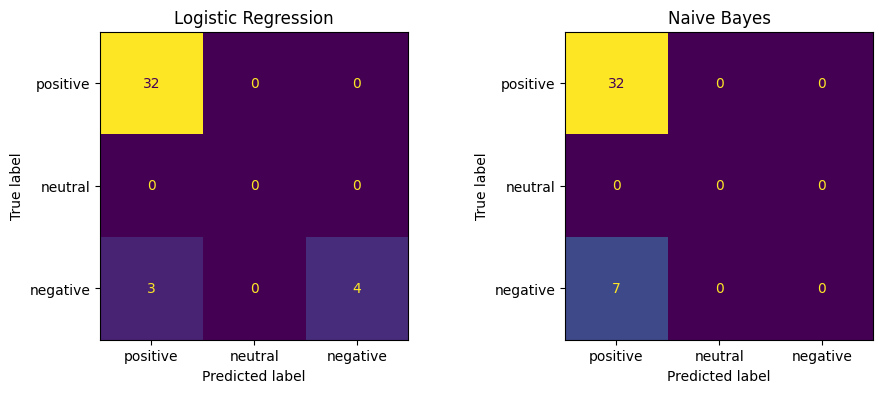

In [49]:
order = ["positive", "neutral", "negative"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(y_test, logreg_pred, labels=order, ax=axes[0], colorbar=False)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(y_test, Naive_pred, labels=order, ax=axes[1], colorbar=False)
axes[1].set_title("Naive Bayes")


based on evaluation metrics on logreg and naive bayes model, The test set has 39 articles: 32 positive, 7 negative and 0 neutral. Naive Bayes predicts "positive" for every article, so it finds none of the 7 negative articles. This explains its accuracy of 0.821 (32 of 39) and its low F1 score. Logistic Regression finds 4 of the 7 negative articles, but still labels 3 of them as positive. So both models lean strongly toward positive.

There is no neutral article in the test set, because DistilBERT labeled only 2 articles neutral in the whole dataset. This means those two models cannot learn a neutral class. this is a clear limitation inherited from the pre-trained labels.

the two metrics defines on what the best approach for this project. Logistic Regression is the better model. it finds some negative articles, while Naive Bayes predicts positive for everything.

##### Hyperparameter tuning

Logistic Regression will be used for the rest of the project, because it performs better than Naive Bayes. it finds some negative articles, while Naive Bayes predicts positive for every article. Hyperparameter tuning will be added to try to improve the model further.

In [53]:
logreg_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(min_df=2)),
    ("clf", LogisticRegression(max_iter=1000))
])

logreg_param = {
    "tfidf__max_features": [2000, 5000],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "clf__C": [0.1, 1, 10]
}

logreg_grid = GridSearchCV(logreg_pipe, logreg_param, cv=5, scoring="f1_macro")
logreg_grid.fit(X_train, y_train)

print("Best Param:", logreg_grid.best_params_)
print("Best f1 cross validation:", round(logreg_grid.best_score_, 3))

c:\conda3\envs\h8_env\lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(


Best Param: {'clf__C': 10, 'tfidf__max_features': 2000, 'tfidf__ngram_range': (1, 2)}
Best f1 cross validation: 0.633


GridSearchCV tried 12 combinations. The best parameters were C = 10, max_features = 2000 and ngram_range = (1, 2), with a cross-validation macro F1 of 0.633. This score is lower than the logreg test score (0.841), but they are not comparable. Then the model will be saved for sentiment analysis

In [55]:
final_model = logreg_grid.best_estimator_
print(final_model)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=2000, min_df=2,
                                 ngram_range=(1, 2))),
                ('clf', LogisticRegression(C=10, max_iter=1000))])
